# COMP 551 Assignment 3

## Task 1: Acquire the data

In [55]:
#!pip install torchvision

In [56]:
import torch
import numpy as np
from torchvision import datasets
from torchvision import transforms
from torch.utils.data import DataLoader

### **Step 1: Load Dataset**

In [57]:
# dataset objects: .data = all images (N, 28, 28), uint8 0-255; .targets = labels
# dataset[i] applies ToTensor -> image [1, 28, 28], float 0-1
train_dataset_raw = datasets.FashionMNIST(root='./data', train=True, download=True,
                                      transform=transforms.ToTensor())
test_dataset_raw = datasets.FashionMNIST(root='./data', train=False, download=True,
                                      transform=transforms.ToTensor())

In [58]:
image, label = train_dataset_raw[0]
print(type(image))
print(image.shape)
print(image.dtype)
print(image.device)
print(f"Train partition: {train_dataset_raw.data.shape} {len(train_dataset_raw)} images")
print(f"Test partition: {test_dataset_raw.data.shape} {len(test_dataset_raw)} images")

<class 'torch.Tensor'>
torch.Size([1, 28, 28])
torch.float32
cpu
Train partition: torch.Size([60000, 28, 28]) 60000 images
Test partition: torch.Size([10000, 28, 28]) 10000 images


### **Step 2: Split Training Partition**

In [59]:
""" Split the default training partition (60k images)
into training and validation partitions """

from torch.utils.data import Subset

split_ratio = 0.8
split_point = int(split_ratio * len(train_dataset_raw))

rng = np.random.default_rng(2026)
indices = np.arange(len(train_dataset_raw))
rng.shuffle(indices)
train_indices = indices[:split_point]
val_indices = indices[split_point:]

train_set = Subset(train_dataset_raw, train_indices)
val_set   = Subset(train_dataset_raw, val_indices)

print(f"Train size: {len(train_set)}")
print(f"Validation size: {len(val_set)}")

Train size: 48000
Validation size: 12000


### **Step 3: Flatten Dataset**

In [60]:
# bring subsets into numpy (raw images)
X_train = train_dataset_raw.data.numpy()[train_indices]
X_val   = train_dataset_raw.data.numpy()[val_indices]
X_test  = test_dataset_raw.data.numpy()

print(f'X_train: {X_train.shape}')
print(f'X_val: {X_val.shape}')
print(f'X_test: {X_test.shape}')

# labels
y_train = train_dataset_raw.targets.numpy()[train_indices]
y_val   = train_dataset_raw.targets.numpy()[val_indices]
y_test  = test_dataset_raw.targets.numpy()

# flatten [vectorize 28*28 = 784]
x_train = X_train.reshape(-1, 784).astype(np.float32) # convert to float
x_val = X_val.reshape(-1, 784).astype(np.float32)
x_test = X_test.reshape(-1, 784).astype(np.float32)

print(f'\nx_val: {x_val.shape}')
print(f'x_train: {x_train.shape}')
print(f'x_test: {x_test.shape}')

# keep unnormalized copies for Q4
x_train_raw, x_val_raw, x_test_raw = x_train.copy(), x_val.copy(), x_test.copy()

X_train: (48000, 28, 28)
X_val: (12000, 28, 28)
X_test: (10000, 28, 28)

x_val: (12000, 784)
x_train: (48000, 784)
x_test: (10000, 784)


### **Step 4: Normalize Dataset**

In [61]:
# normalization statistics from the training split only (not validation)
# this method based on numpy simplicity in the CS231n data processing reference

mean = x_train.mean()
std = x_train.std()
print(f'train mean: {mean:.3f}, train std: {std:.3f}')

# apply the same mean and std to all three sets
x_train = (x_train - mean) / std
x_val   = (x_val - mean) / std
x_test  = (x_test - mean) / std

print(f'train: mean {x_train.mean():.3f}, std {x_train.std():.3f}')
print(f'val:   mean {x_val.mean():.3f}, std {x_val.std():.3f}')
print(f'test:  mean {x_test.mean():.3f}, std {x_test.std():.3f}')

train mean: 72.877, train std: 90.006
train: mean 0.000, std 1.000
val:   mean 0.003, std 1.001
test:  mean 0.003, std 0.999


### **Step 5: Exploratory Data Analysis**

In [62]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

#### 1. Dataset structure

In [63]:
for root, dirs, files in os.walk('./data/FashionMNIST'):

    level = root.replace('./data/FashionMNIST', "").count(os.sep)

    indent = " " * 4 * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:]:
        print(f"{indent}    {file}")

print(train_dataset_raw)
print("Images shape:", train_dataset_raw.data.shape)
print("Labels shape:", train_dataset_raw.targets.shape)
class_names = train_dataset_raw.classes

print("Number of classes:", len(class_names))
for class_id, class_name in enumerate(class_names):
    print(class_id, class_name)


FashionMNIST/
    raw/
        t10k-images-idx3-ubyte
        t10k-labels-idx1-ubyte
        train-images-idx3-ubyte
        t10k-images-idx3-ubyte.gz
        train-images-idx3-ubyte.gz
        train-labels-idx1-ubyte.gz
        train-labels-idx1-ubyte
        t10k-labels-idx1-ubyte.gz
Dataset FashionMNIST
    Number of datapoints: 60000
    Root location: ./data
    Split: Train
    StandardTransform
Transform: ToTensor()
Images shape: torch.Size([60000, 28, 28])
Labels shape: torch.Size([60000])
Number of classes: 10
0 T-shirt/top
1 Trouser
2 Pullover
3 Dress
4 Coat
5 Sandal
6 Shirt
7 Sneaker
8 Bag
9 Ankle boot


#### 2. Class Distribution - images per category

         Class  Train  Validation  Test  Total
0  T-shirt/top   4755        1245  1000   7000
1      Trouser   4852        1148  1000   7000
2     Pullover   4803        1197  1000   7000
3        Dress   4810        1190  1000   7000
4         Coat   4775        1225  1000   7000
5       Sandal   4819        1181  1000   7000
6        Shirt   4791        1209  1000   7000
7      Sneaker   4765        1235  1000   7000
8          Bag   4834        1166  1000   7000
9   Ankle boot   4796        1204  1000   7000


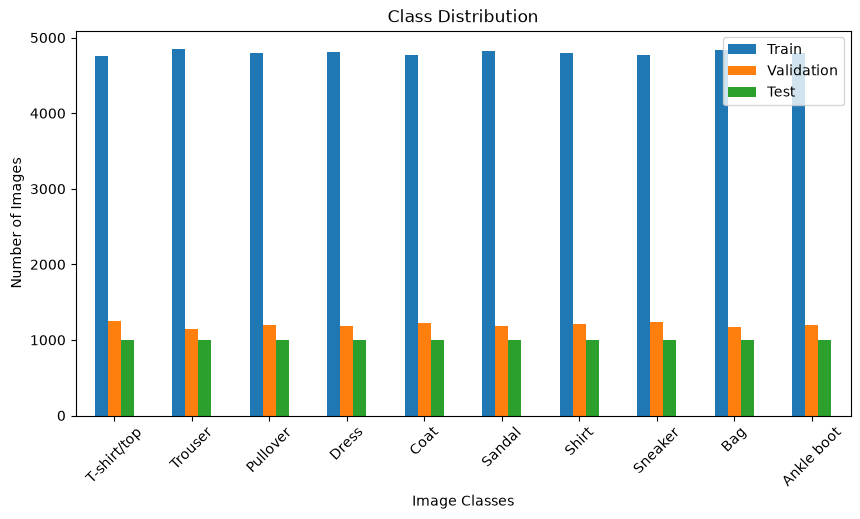

In [64]:
class_names = train_dataset_raw.classes

splits = {
    "Train": y_train,
    "Validation": y_val,
    "Test": y_test
}

class_counts = {"Class": class_names}

for split_name, labels in splits.items():
    class_counts[split_name] = np.bincount(labels, minlength=10)

class_df = pd.DataFrame(class_counts)
class_df["Total"] = class_df[["Train", "Validation", "Test"]].sum(axis=1)

print(class_df)

class_df.plot(
    kind="bar",
    x="Class",
    y=["Train", "Validation", "Test"],
    figsize=(10, 5)
)

plt.title("Class Distribution")
plt.xlabel("Image Classes")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.show()

#### 3. Random raw images

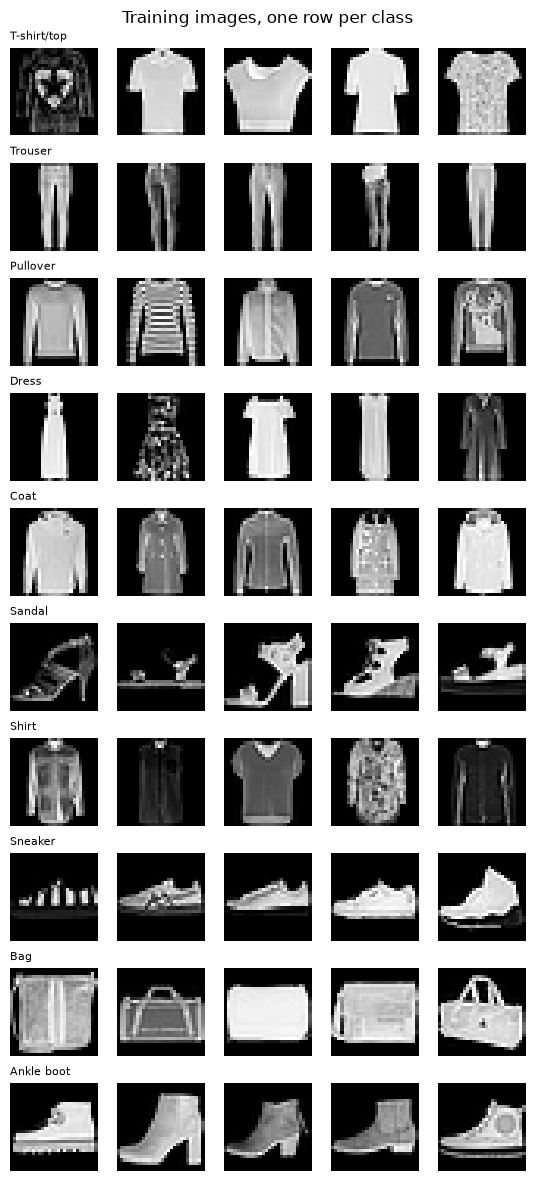

In [65]:
n_show = 5
fig, axes = plt.subplots(10, n_show, figsize=(n_show * 1.1, 10 * 1.2))
for c in range(10):
    examples = np.where(y_train == c)[0][:n_show]
    for j, i in enumerate(examples):
        axes[c, j].imshow(x_train[i].reshape(28, 28), cmap='gray')
        axes[c, j].axis('off')
    axes[c, 0].set_title(class_names[c], fontsize=8, loc='left')
plt.suptitle('Training images, one row per class')
plt.tight_layout()
plt.show()

#### 4.Pixel distribution — mean, std, intensity

raw train pixels: mean 72.88, std 90.01


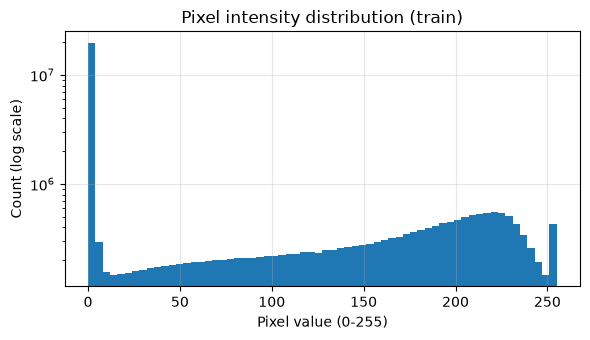

In [66]:
x_all_train = train_dataset_raw.data.numpy()
y_all_train = train_dataset_raw.targets.numpy()
x_all_test  = test_dataset_raw.data.numpy()
y_all_test  = test_dataset_raw.targets.numpy()

X_train_hist = x_all_train[train_indices]   # same split as the rest of the notebook

print(f'raw train pixels: mean {X_train_hist.mean():.2f}, std {X_train_hist.std():.2f}')

plt.figure(figsize=(6, 3.5))
plt.hist(X_train_hist.ravel(), bins=64, log=True)
plt.xlabel('Pixel value (0-255)')
plt.ylabel('Count (log scale)')
plt.title('Pixel intensity distribution (train)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#### 5. Data integrity -- corrupted images


In [67]:
invalid = []
for i in range(len(train_dataset_raw)):              # reading every image like during training
    try:
        img, lable = train_dataset_raw[i]
    except Exception as e:
        invalid.append(("train", i))
for i in range(len(test_dataset_raw)):
    try:
        img, lable = test_dataset_raw[i]
    except Exception as e:
        invalid.append(('test', i))
print(f"Invalid images: {len(invalid)}")

for name, x, y in [('train partition', x_all_train, y_all_train), ('test partition', x_all_test, y_test)]:
    print(f"\n{name}:")
    print(f"  all images 28x28:        {x.shape[1:] == (28, 28)}")
    print(f"  pixel range:             [{x.min()}, {x.max()}]")
    print(f"  NaN values:              {np.isnan(x.astype(float)).sum()}")
    print(f"  labels in [0,9]:          {set(np.unique(y)) <= set(range(10))}")
    print(f"  completely blank images: {(x.reshape(len(x), -1).max(axis=1) == 0).sum()}")

Invalid images: 0

train partition:
  all images 28x28:        True
  pixel range:             [0, 255]
  NaN values:              0
  labels in [0,9]:          True
  completely blank images: 0

test partition:
  all images 28x28:        True
  pixel range:             [0, 255]
  NaN values:              0
  labels in [0,9]:          True
  completely blank images: 0


#### 6. Data leakage

In [68]:
# 6.1 image index in both training and validation
print(f"Indices shared by train and validation: {len(set(train_indices) & set(val_indices))}")

Indices shared by train and validation: 0


## Task 2: Implement a Multilayer Perceptron

Our model is an MLP with $L-1$ hidden layers and a softmax output layer:

$$
z_0 = x, \qquad
a_l = z_{l-1} W_l + b_l, \qquad
z_l = h(a_l) \quad \text{for } l = 1, \dots, L-1
$$

$$
\hat{y} = \operatorname{softmax}(a_L), \qquad a_L = z_{L-1} W_L + b_L
$$

$x$ is the flattened image (784 pixels), $h$ is the hidden activation function, $W_l$ and $b_l$ are the weights and bias for layer $l$, and $\hat{y}$ is the output probability of each of the 10 categories (softmax since it's multi-class).


An MLP is composed of three types of layers: 

(1) an input layer -> flattened 784 pixels

(2) hidden layers -> every layer: $z = h(Wx+b)$ (linear transformation -> activation function)

    - Activation Function: ReLU, Tanh, Leaky-ReLU

(3) an output layer -> the probability of 10 categories $\left ( \operatorname{softmax}(u)_k = \frac{\exp(u_k)}{\sum_j \exp(u_j)} \right )$

(4)Loss: 


$$L = -\frac{1}{N}\sum_{n}\sum_{k} y_{nk}\log \hat{y}_{nk}, \quad \hat{y} = \text{softmax}(a)$$

**Forward Pass:**

x --W1--> a1 --h--> z1 --W2--> a2 --h--> z2..... --Wl--> al --softmax--> yh --> L

#### Gradient

- Taking the derivative with respect to the last layer's pre-activation `a`:

$$\frac{\partial L}{\partial a} = \frac{\hat{y} - y}{N}$$

- $a = zW + b$

$$\frac{\partial L}{\partial w} = z^{T}  \frac{\partial L}{\partial a}$$
$$\frac{\partial L}{\partial z} = \frac{\partial L}{\partial a} w^{T}$$

*Chain Rule*

For $ z = h(a_{l-1})$

$$\frac{\partial L}{\partial a_{l-1}} =  h'(a_{l-1}) \odot \frac{\partial L}{\partial z}$$

- h(): activation function 

Implementation should include 

    - backpropagation 

    - mini-batch gradient descent algorithm

- [] gamma is also a learnable parameter  
- Weight Initialization

| Method                | Common application | Main idea                                      |
|-----------------------|--------------------|------------------------------------------------|
| Zero initialization   | Biases             | Initialize biases to zero                      |
| Random initialization | General concept    | Start weights with random values               |
| Xavier (Glorot)       | Tanh, sigmoid      | $\operatorname{Var}(W)=\frac{2}{n_{in}+n_{out}}$ |
| He (Kaiming)          | ReLU, Leaky ReLU   | $\operatorname{Var}(W)=\frac{2}{n_{in}}$         |


In [69]:
#Activation Function
relu = lambda a: np.maximum(0, a)
relu_grad = lambda a: (a > 0).astype(float)                          

tanh = lambda a: np.tanh(a)
tanh_grad = lambda a: 1 - np.tanh(a) ** 2                            

leaky_relu = lambda a: np.maximum(0, a) + 0.01 * np.minimum(0, a)     
leaky_relu_grad = lambda a: np.where(a > 0, 1., 0.01)

activations = {'relu': (relu, relu_grad),
               'tanh': (tanh, tanh_grad),
               'leaky_relu': (leaky_relu, leaky_relu_grad)}

In [70]:
#The constructor for the class should take as input 
# the activation function (e.g., ReLU), 
# the number of hidden layers (e.g., 2) 
# the number of units in the hidden layers (e.g., [64, 64]) 
# initialize the weights and biases (with an initializer of your choice) 
# as well as other important properties of the MLP.
def one_hot(y, C):
    Y = np.zeros((len(y), C))
    Y[np.arange(len(y)), y] = 1                 # e.g. label 3 -> [0,0,0,1,0,0,0,0,0,0]
    return Y

def softmax(a):
    a = a - np.max(a, axis=1, keepdims=True)    
    e = np.exp(a)
    return e / np.sum(e, axis=1, keepdims=True)

class MLP:
    
    def __init__(self, activation, n_hidden_layers, hidden_units, n_input , n_output, init = "auto"):
        '''
        Initialize a multilayer perceptron with a softmax output layer.

        Architecture: x -> [W1,b1] -> h -> [W2,b2] -> h -> ... -> [WL,bL] -> softmax -> yh

        Parameters:
        activation: hidden activation, 'relu', 'tanh' or 'leaky_relu'
        n_hidden_layers: number of hidden layers 
        hidden_units: list with the number of units of each hidden layer
        n_input: number of input features D
        n_output: number of classes C
        init: ReLU, Leaky ReLU, Tanh or auto for 0.01
        '''
        self.activation = activation
        self.n_hidden_layers = n_hidden_layers
        self.hidden_units = hidden_units
        self.h, self.h_grad = activations[activation]
        self.input_dim = n_input
        self.output_dim = n_output
        self.init = init
        
        self.layer_sizes = [n_input] +list(hidden_units)+[n_output]
        # Store parameters as a list for the optimizer
        self.params = [] # [W1,b1,W2,b2,...,Wl,bl]

        for n_in, n_out in zip(self.layer_sizes[:-1], self.layer_sizes[1:]):
            if init == 'relu' or init == "leaky_relu":
                scale = np.sqrt(2 / n_in)
            elif init == 'tanh':
                scale = np.sqrt(2 / (n_in + n_out))
            elif init == 'auto':
                scale = .01
            else:
                raise ValueError(f"Unknown init: {init}")
            W = np.random.randn(n_in, n_out) * scale  # W_{i} (n_in, n_out)
            b = np.zeros(n_out)                         # (n_out,)

            self.params.extend([W, b])
            
    def forward(self, x, params):
        """
        Forward pass through the network.
        
        Parameters:
        x: input features, shape (N, D)
        params: [W1,b1,W2,b2,...,Wl,bl]
        Returns:
        out: predicted probabilities, shape (N, 10)
        
        """
        L = len(params) // 2 # number of layers [W1,b1,W2,b2,...,Wl,bl]
        z = x
        h_u, p_a = [x],[]  
        for l in range(L):
            W, b = params[2*l], params[2*l+1]
            a = np.dot(z, W) + b # pre-activation 
            p_a.append(a) 
            if l < L - 1:   # without output layer, all hidden layers go through activation function
                z = self.h(a) # after activation
                h_u.append(z)     # h_u[l] the input of l-th layer
        yh = softmax(a)

        return yh, h_u, p_a
    
    def gradient(self, x, y, params):
        """
        Compute gradients for both layers using backpropagation.
        
        Parameters:
        x: input features, shape (N, D)
        y: true labels, shape (N,)
        params: list [w1, b1... wL, bL] 
        
        Returns:
        params: list [dw1, db1... dwL, dbL] containing gradients for W and b
        """
        N = x.shape[0]
        L = len(params) // 2 
        yh, h_u, p_a = self.forward(x, params)
        # Store gradients
        dparams = [None] * len(params) #[dW1, db1, dW2, db2, ...]
        
        da = (yh - one_hot(y, yh.shape[1])) / N # the derivative with respect to the last layer's pre-activation

        for l in reversed(range(L)):
             W = params[2 * l]
             dW = np.dot(h_u[l].T, da)
             db = np.sum(da, axis=0)
             dparams[2 * l], dparams[2 * l + 1] = dW, db
             if l > 0:
                dz = np.dot(da, W.T)
                da = dz * self.h_grad(p_a[l - 1])

        return dparams
    
            
    def fit(self, x, y, optimizer):
       
        self.params = optimizer.run(self.gradient, x, y, self.params)
        return self

    def predict(self, x):
        yh, _, _ = self.forward(x, self.params)
        return np.argmax(yh, axis=1)
    
def evaluate_acc(y, yh):                    
    return np.mean(y == yh)
        
 

### Mini-batch gradient descent (batch_size config)

In [71]:
class GradientDescent:

    # batch_size: N = full-batch GD, 64 = mini-batch (default), 1 = SGD
    def __init__(self, learning_rate, epochs = 10, batch_size = 64):

        self.learning_rate = learning_rate
        self.epochs = epochs
        self.batch_size = batch_size
        
    def run(self, gradient_fn, x, y, params):

        N = x.shape[0] 
        for epoch in range(self.epochs):
            # shuffle the training data every epoch
            order = np.random.permutation(N)

            # select a batch of `batch_size` samples each time
            for i in range(0, N, self.batch_size):
                batch = order[i : i+self.batch_size]
                grad = gradient_fn(x[batch], y[batch], params)
                for p in range(len(params)):
                    params[p] -= self.learning_rate * grad[p]


            print(f"Epoch {epoch + 1}/{self.epochs} done")
        return params

In [72]:
np.random.seed(2026) # reset global RNG: same initial weights & GradientDescent shuffling, so runs are reproducible
model = MLP(activation='relu', n_hidden_layers=2, hidden_units=[256, 256],
            n_input=784, n_output=10, init='relu')
optimizer = GradientDescent(learning_rate=0.05, epochs=3, batch_size=64)
model.fit(x_train, y_train, optimizer)

print(evaluate_acc(y_val, model.predict(x_val)))   

Epoch 1/3 done
Epoch 2/3 done
Epoch 3/3 done
0.87575
